<a href="https://colab.research.google.com/github/SithmiDesilva/Hallucination-Aware-AI-Framework-for-Trustworthy-Supply-Chain-Decision-Intelligence.-/blob/M5_Forecasting_Preprocessing/M5_Forecasting_Sell_Prices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## SECTION 1: DATA LOADING

In [1]:
# ============================================================================
# NOTEBOOK 4: SELL PRICES DATASET PREPROCESSING
# ============================================================================
# This notebook handles the sell_prices.csv dataset
# It performs preprocessing, outlier detection, and data quality checks
# ============================================================================

# ----------------------------------------------------------------------------
# SECTION 1: SETUP AND DATA LOADING
# ----------------------------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 6)

from google.colab import drive
drive.mount('/content/drive')

# Load the sell prices dataset
sell_prices = pd.read_csv('/content/drive/MyDrive/IRP/M5 Forecasting dataset/sell_prices.csv')


Mounted at /content/drive


In [2]:
print("=" * 80)
print("SELL PRICES DATASET - INITIAL EXPLORATION")
print("=" * 80)
print(f"\nDataset Shape: {sell_prices.shape}")
print(f"Columns: {sell_prices.columns.tolist()}")
print(f"\nFirst 5 rows:")
display(sell_prices.head())

SELL PRICES DATASET - INITIAL EXPLORATION

Dataset Shape: (6841121, 4)
Columns: ['store_id', 'item_id', 'wm_yr_wk', 'sell_price']

First 5 rows:


,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


## SECTION 2: INITIAL DATA EXPLORATION (BEFORE PREPROCESSING)

In [3]:
# 2.1 Basic statistics
print("\n--- Basic Statistics ---")
print(sell_prices.describe())

print(f"\n--- Unique Values ---")
print(f"Unique stores: {sell_prices['store_id'].nunique()}")
print(f"Unique items: {sell_prices['item_id'].nunique()}")
print(f"Unique weeks: {sell_prices['wm_yr_wk'].nunique()}")
print(f"Week range: {sell_prices['wm_yr_wk'].min()} to {sell_prices['wm_yr_wk'].max()}")


--- Basic Statistics ---
           wm_yr_wk    sell_price
count  6.841121e+06  6.841121e+06
mean   1.138294e+04  4.410952e+00
std    1.486100e+02  3.408814e+00
min    1.110100e+04  1.000000e-02
25%    1.124700e+04  2.180000e+00
50%    1.141100e+04  3.470000e+00
75%    1.151700e+04  5.840000e+00
max    1.162100e+04  1.073200e+02

--- Unique Values ---
Unique stores: 10
Unique items: 3049
Unique weeks: 282
Week range: 11101 to 11621


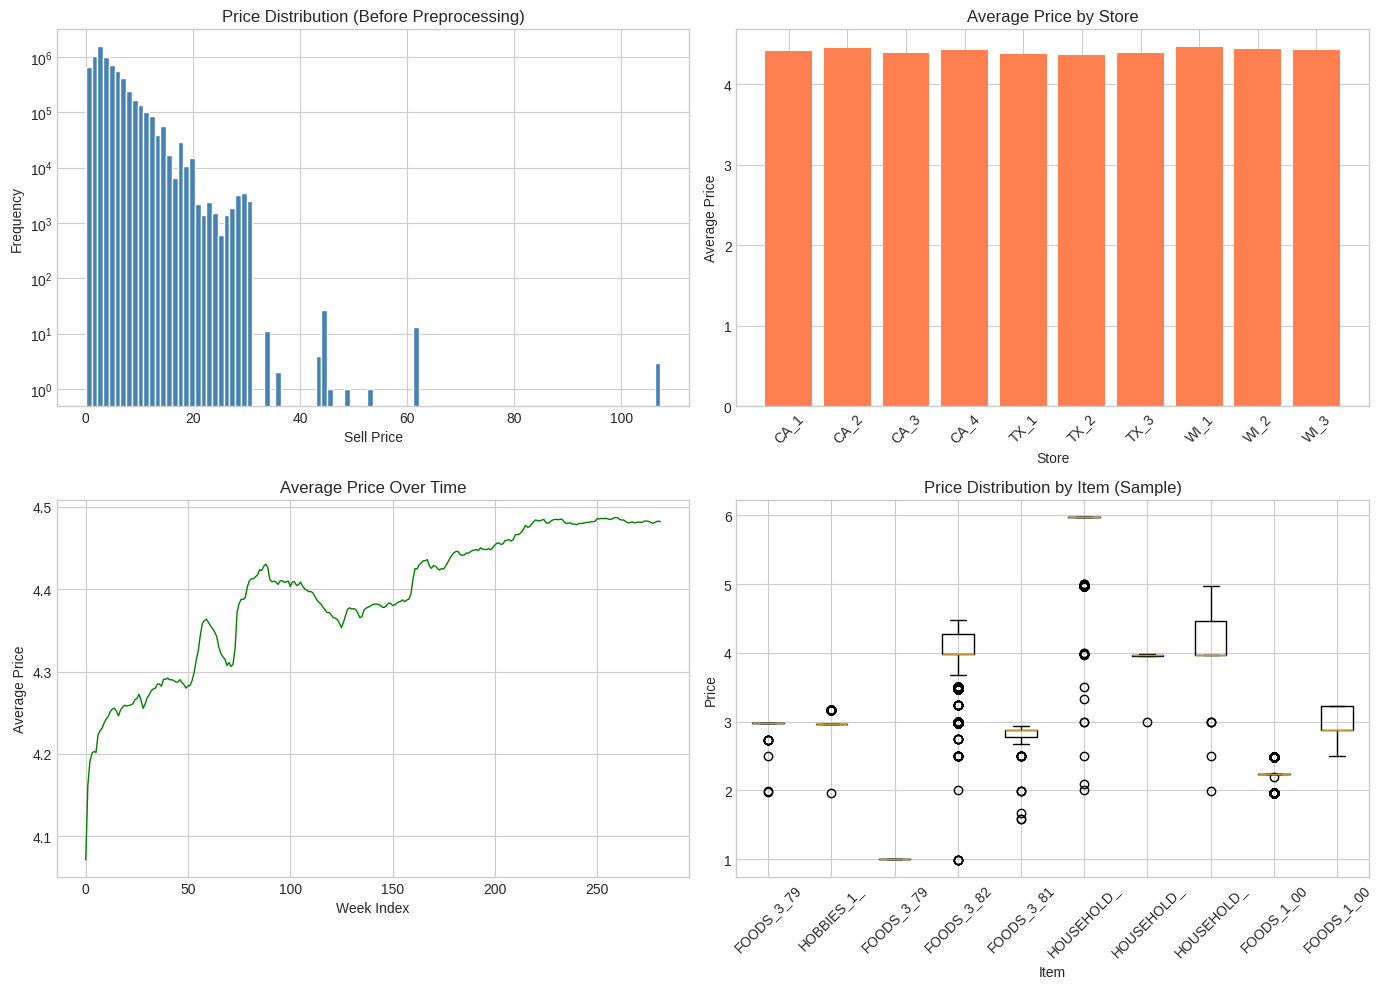

In [6]:
# 2.2 Visualize price distribution before preprocessing
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Price distribution
axes[0, 0].hist(sell_prices['sell_price'], bins=100, color='steelblue', edgecolor='white')
axes[0, 0].set_xlabel('Sell Price')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Price Distribution (Before Preprocessing)')
axes[0, 0].set_yscale('log')

# Price by store
store_prices = sell_prices.groupby('store_id')['sell_price'].mean()
axes[0, 1].bar(store_prices.index.astype(str), store_prices.values, color='coral')
axes[0, 1].set_xlabel('Store')
axes[0, 1].set_ylabel('Average Price')
axes[0, 1].set_title('Average Price by Store')
axes[0, 1].tick_params(axis='x', rotation=45)

# Price over time
weekly_prices = sell_prices.groupby('wm_yr_wk')['sell_price'].mean()
axes[1, 0].plot(range(len(weekly_prices)), weekly_prices.values, color='green', linewidth=1)
axes[1, 0].set_xlabel('Week Index')
axes[1, 0].set_ylabel('Average Price')
axes[1, 0].set_title('Average Price Over Time')

# Price boxplot by item (sample)
sample_items = sell_prices['item_id'].value_counts().head(20).index
sample_data = sell_prices[sell_prices['item_id'].isin(sample_items)]
item_price_data = [sample_data[sample_data['item_id'] == item]['sell_price'].values
                   for item in sample_items[:10]]
axes[1, 1].boxplot(item_price_data, labels=[str(i)[:10] for i in sample_items[:10]])
axes[1, 1].set_xlabel('Item')
axes[1, 1].set_ylabel('Price')
axes[1, 1].set_title('Price Distribution by Item (Sample)')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('sell_prices_before_preprocessing.png', dpi=150, bbox_inches='tight')
plt.show()


## SECTION 3: PREPROCESSING

In [11]:
# Create copy
sell_prices_processed = sell_prices.copy()

# 3.1 Convert types

sell_prices_processed['store_id'] = sell_prices_processed['store_id'].astype('category')
sell_prices_processed['item_id'] = sell_prices_processed['item_id'].astype('category')
sell_prices_processed['wm_yr_wk'] = sell_prices_processed['wm_yr_wk'].astype(int)
sell_prices_processed['sell_price'] = sell_prices_processed['sell_price'].astype(float)
print("Types converted: store_id, item_id -> category; wm_yr_wk -> int; sell_price -> float")


Types converted: store_id, item_id -> category; wm_yr_wk -> int; sell_price -> float


In [12]:
# 3.2 Create composite key

sell_prices_processed['item_store_id'] = (sell_prices_processed['item_id'].astype(str) + '_' +
                                          sell_prices_processed['store_id'].astype(str))
print("item_store_id created")


item_store_id created


In [25]:
# 3.3 Calculate price statistics by item-store

# Ensure item_store_id is represented as a string on both sides for robust alignment
sell_prices_processed['item_store_id'] = sell_prices_processed['item_store_id'].astype(str)

item_store_price_stats = sell_prices_processed.groupby('item_store_id')['sell_price'].agg(
    ['mean', 'std', 'min', 'max', 'count']
).reset_index()

item_store_price_stats.columns = ['item_store_id', 'price_mean', 'price_std', 'price_min',
                                   'price_max', 'price_count']

# Safe merge: Drop the columns if they already exist from a previous execution to prevent duplicate suffix errors
stat_cols = ['price_mean', 'price_std', 'price_min', 'price_max', 'price_count']
sell_prices_processed = sell_prices_processed.drop(columns=[col for col in stat_cols if col in sell_prices_processed.columns])

# Perform a clean left merge
sell_prices_processed = sell_prices_processed.merge(item_store_price_stats,
                                                     on='item_store_id', how='left')

# Convert item_store_id to categorical to save memory now that the merge is completed
sell_prices_processed['item_store_id'] = sell_prices_processed['item_store_id'].astype('category')

# --- Display proper validation outputs ---
print(f"\nMerged successfully! New DataFrame shape: {sell_prices_processed.shape}")
print(f"Number of unique item-store combinations: {item_store_price_stats.shape[0]:,}")

if all(col in sell_prices_processed.columns for col in stat_cols):
    print("\n[1] Summary Statistics of the Features:")
    print(sell_prices_processed[stat_cols].describe())

    print("\n[2] Checking for Missing Values in New Columns:")
    print(sell_prices_processed[stat_cols].isnull().sum())

    print("\n[3] Sample of the Preprocessed Data (showing computed stats):")
    display(sell_prices_processed[['item_store_id', 'sell_price'] + stat_cols[:-1]].head(5))
else:
    print("\n[Error] The requested statistics columns are missing from the merged DataFrame.")
print("=" * 80)


Merged successfully! New DataFrame shape: (6841121, 29)
Number of unique item-store combinations: 30,490

[1] Summary Statistics of the Features:
         price_mean     price_std     price_min     price_max   price_count
count  6.841121e+06  6.841121e+06  6.841121e+06  6.841121e+06  6.841121e+06
mean   4.410952e+00  1.483823e-01  3.942627e+00  4.608173e+00  2.449810e+02
std    3.397673e+00  2.326368e-01  3.212718e+00  3.631536e+00  5.461714e+01
min    1.915248e-01  0.000000e+00  1.000000e-02  2.300000e-01  1.900000e+01
25%    2.165780e+00  1.001727e-02  1.960000e+00  2.280000e+00  2.170000e+02
50%    3.422414e+00  9.543351e-02  2.970000e+00  3.580000e+00  2.800000e+02
75%    5.795743e+00  2.042630e-01  4.980000e+00  5.970000e+00  2.820000e+02
max    3.050578e+01  1.258371e+01  2.997000e+01  1.073200e+02  2.820000e+02

[2] Checking for Missing Values in New Columns:
price_mean     0
price_std      0
price_min      0
price_max      0
price_count    0
dtype: int64

[3] Sample of the Pre

,item_store_id,sell_price,price_mean,price_std,price_min,price_max
0,FOODS_1_001_CA_1,2.0,2.169362,0.109572,2.0,2.24
1,FOODS_1_001_CA_1,2.0,2.169362,0.109572,2.0,2.24
2,FOODS_1_001_CA_1,2.0,2.169362,0.109572,2.0,2.24
3,FOODS_1_001_CA_1,2.0,2.169362,0.109572,2.0,2.24
4,FOODS_1_001_CA_1,2.0,2.169362,0.109572,2.0,2.24


In [26]:
# 3.4 Add derived features

sell_prices_processed['price_variation'] = (sell_prices_processed['price_std'] /
                                            (sell_prices_processed['price_mean'] + 1e-6))
sell_prices_processed['price_range'] = (sell_prices_processed['price_max'] -
                                        sell_prices_processed['price_min'])
sell_prices_processed['is_constant_price'] = (sell_prices_processed['price_std'] == 0).astype(int)

# --- Display proper validation outputs ---

print(f"\nDerived features added successfully! Current shape: {sell_prices_processed.shape}")

derived_cols = ['price_variation', 'price_range', 'is_constant_price']

print("\n[1] Descriptive Statistics of Derived Features:")
print(sell_prices_processed[derived_cols].describe())

print("\n[2] Checking for Missing / Infinite Values:")
print("Missing values:")
print(sell_prices_processed[derived_cols].isnull().sum())
print("Infinite values:")
print(np.isinf(sell_prices_processed[derived_cols]).sum())

print("\n[3] Constant Price vs. Varying Price Counts:")
print(sell_prices_processed['is_constant_price'].value_counts())

print("\n[4] Sample of Processed Data with Derived Features:")
display(sell_prices_processed[['item_store_id', 'sell_price', 'price_mean', 'price_variation', 'price_range', 'is_constant_price']].head(5))



Derived features added successfully! Current shape: (6841121, 29)

[1] Descriptive Statistics of Derived Features:
       price_variation   price_range  is_constant_price
count     6.841121e+06  6.841121e+06       6.841121e+06
mean      3.594110e-02  6.655454e-01       2.186532e-01
std       3.802962e-02  1.369815e+00       4.133328e-01
min       0.000000e+00  0.000000e+00       0.000000e+00
25%       3.289895e-03  3.000000e-02       0.000000e+00
50%       3.051005e-02  3.200000e-01       0.000000e+00
75%       5.392318e-02  8.000000e-01       0.000000e+00
max       9.747098e-01  1.040600e+02       1.000000e+00

[2] Checking for Missing / Infinite Values:
Missing values:
price_variation      0
price_range          0
is_constant_price    0
dtype: int64
Infinite values:
price_variation      0
price_range          0
is_constant_price    0
dtype: int64

[3] Constant Price vs. Varying Price Counts:
is_constant_price
0    5345288
1    1495833
Name: count, dtype: int64

[4] Sample of Process

,item_store_id,sell_price,price_mean,price_variation,price_range,is_constant_price
0,FOODS_1_001_CA_1,2.0,2.169362,0.050509,0.24,0
1,FOODS_1_001_CA_1,2.0,2.169362,0.050509,0.24,0
2,FOODS_1_001_CA_1,2.0,2.169362,0.050509,0.24,0
3,FOODS_1_001_CA_1,2.0,2.169362,0.050509,0.24,0
4,FOODS_1_001_CA_1,2.0,2.169362,0.050509,0.24,0


In [27]:
# 3.5 Sort and calculate price changes
sell_prices_processed = sell_prices_processed.sort_values(['item_id', 'store_id', 'wm_yr_wk']).reset_index(drop=True)

sell_prices_processed['price_lag_1'] = sell_prices_processed.groupby('item_store_id')['sell_price'].shift(1)
sell_prices_processed['price_change'] = (sell_prices_processed['sell_price'] -
                                         sell_prices_processed['price_lag_1'])
sell_prices_processed['price_change_pct'] = ((sell_prices_processed['price_change'] /
                                              (sell_prices_processed['price_lag_1'] + 1e-6)) * 100)

# Price change flags
sell_prices_processed['price_increased'] = (sell_prices_processed['price_change'] > 0).astype(int)
sell_prices_processed['price_decreased'] = (sell_prices_processed['price_change'] < 0).astype(int)
sell_prices_processed['price_unchanged'] = (sell_prices_processed['price_change'] == 0).astype(int)

# --- Display proper validation outputs ---

print(f"\nProcessing complete! Current shape: {sell_prices_processed.shape}")

change_cols = ['price_change', 'price_change_pct']
flag_cols = ['price_increased', 'price_decreased', 'price_unchanged']

print("\n[1] Descriptive Statistics of Price Changes:")
print(sell_prices_processed[change_cols].describe())

print("\n[2] Checking Missing Values (NaN expected on first week per item-store):")
print(sell_prices_processed[['price_lag_1'] + change_cols].isnull().sum())

print("\n[3] Distribution of Price Change Flags (Unchanged includes first week NaNs):")
for col in flag_cols:
    counts = sell_prices_processed[col].value_counts()
    pct = sell_prices_processed[col].value_counts(normalize=True) * 100
    print(f"  {col:15s}: {counts[1]:,d} occurrences ({pct[1]:.2f}% of total data)")

print("\n[4] Sample Data showing Price Transitions:")
# Show transitions for a single item-store where variations are present
sample_key = sell_prices_processed[sell_prices_processed['price_change'] != 0]['item_store_id'].iloc[0]
sample_subset = sell_prices_processed[sell_prices_processed['item_store_id'] == sample_key]
display(sample_subset[['wm_yr_wk', 'sell_price', 'price_lag_1', 'price_change', 'price_change_pct', 'price_increased', 'price_decreased']].head(6))



Processing complete! Current shape: (6841121, 29)

[1] Descriptive Statistics of Price Changes:
       price_change  price_change_pct
count  6.810631e+06      6.810631e+06
mean   4.045616e-04      1.244777e-01
std    1.534546e-01      4.506761e+01
min   -9.486000e+01     -9.988863e+01
25%    0.000000e+00      0.000000e+00
50%    0.000000e+00      0.000000e+00
75%    0.000000e+00      0.000000e+00
max    9.486000e+01      8.969103e+04

[2] Checking Missing Values (NaN expected on first week per item-store):
price_lag_1         30490
price_change        30490
price_change_pct    30490
dtype: int64

[3] Distribution of Price Change Flags (Unchanged includes first week NaNs):
  price_increased: 45,212 occurrences (0.66% of total data)
  price_decreased: 33,603 occurrences (0.49% of total data)
  price_unchanged: 6,731,816 occurrences (98.40% of total data)

[4] Sample Data showing Price Transitions:


,wm_yr_wk,sell_price,price_lag_1,price_change,price_change_pct,price_increased,price_decreased
0,11101,2.0,NaN,NaN,NaN,0,0
1,11102,2.0,2.0,0.0,0.0,0,0
2,11103,2.0,2.0,0.0,0.0,0,0
3,11104,2.0,2.0,0.0,0.0,0,0
4,11105,2.0,2.0,0.0,0.0,0,0
5,11106,2.0,2.0,0.0,0.0,0,0


In [31]:
# 3.6 Rolling statistics
sell_prices_processed['price_rolling_mean_3'] = sell_prices_processed.groupby('item_store_id')['sell_price'].transform(
    lambda x: x.rolling(3, min_periods=1).mean()
)
sell_prices_processed['price_rolling_mean_7'] = sell_prices_processed.groupby('item_store_id')['sell_price'].transform(
    lambda x: x.rolling(7, min_periods=1).mean()
)

# --- Display proper validation outputs ---
print(f"\nRolling features successfully calculated! Current shape: {sell_prices_processed.shape}")

rolling_cols = ['price_rolling_mean_3', 'price_rolling_mean_7']

print("\n[1] Descriptive Statistics of Rolling Means:")
print(sell_prices_processed[['sell_price'] + rolling_cols].describe())

print("\n[2] Checking for Missing Values (None expected due to min_periods=1):")
print(sell_prices_processed[rolling_cols].isnull().sum())

print("\n[3] Comparative Sample displaying Rolling Trends:")
# Use the same sample_key from price changes for consistent tracking
sample_key = sell_prices_processed[sell_prices_processed['price_change'] != 0]['item_store_id'].iloc[0]
sample_subset = sell_prices_processed[sell_prices_processed['item_store_id'] == sample_key]
display(sample_subset[['wm_yr_wk', 'sell_price', 'price_rolling_mean_3', 'price_rolling_mean_7']].head(8))



Rolling features successfully calculated! Current shape: (6841121, 31)

[1] Descriptive Statistics of Rolling Means:
         sell_price  price_rolling_mean_3  price_rolling_mean_7
count  6.841121e+06          6.841121e+06          6.841121e+06
mean   4.410952e+00          4.410549e+00          4.409752e+00
std    3.408814e+00          3.407367e+00          3.406102e+00
min    1.000000e-02          1.000000e-02          8.000000e-02
25%    2.180000e+00          2.180000e+00          2.180000e+00
50%    3.470000e+00          3.470000e+00          3.470000e+00
75%    5.840000e+00          5.840000e+00          5.840000e+00
max    1.073200e+02          1.073200e+02          6.146000e+01

[2] Checking for Missing Values (None expected due to min_periods=1):
price_rolling_mean_3    0
price_rolling_mean_7    0
dtype: int64

[3] Comparative Sample displaying Rolling Trends:


,wm_yr_wk,sell_price,price_rolling_mean_3,price_rolling_mean_7
0,11101,2.0,2.0,2.0
1,11102,2.0,2.0,2.0
2,11103,2.0,2.0,2.0
3,11104,2.0,2.0,2.0
4,11105,2.0,2.0,2.0
5,11106,2.0,2.0,2.0
6,11107,2.0,2.0,2.0
7,11108,2.0,2.0,2.0
